### STUDENT DEPRESSION

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import warnings
warnings.filterwarnings("ignore")

Creare booleano is_night in base all'orario

In [3]:
path_file = r'Student_Depression_Dataset.csv'
df = pd.read_csv(path_file)
df.head(10)


,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes
5,Female,24,Middle class,Single,Unmarried,Bachelor,9,3.80,Yes,Normal,17244,Chittagong,No
6,Female,21,Lower Middle class,Single,Unmarried,Family,9,3.50,Yes,Normal,1648,Dhaka,No
7,Female,19,Middle class,Single,Unmarried,Family,2,2.71,Yes,Abnormal,16782,Rajshahi,Yes
8,Female,21,Middle class,Single,Unmarried,Family,3,3.10,Yes,Abnormal,13386,Dhaka,Yes
9,Female,22,Middle class,In a Relationship,Married,Family,4,3.34,Yes,Normal,18131,Mymensingh,No


In [4]:
df.tail()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
4459,Female,26,Middle class,In a Relationship,Separated,Family,11,2.97,No,Critical,12619,Khulna,Yes
4460,Male,28,Lower Middle class,Single,Unmarried,Family,8,2.60,No,Normal,2806,Rajshahi,Yes
4461,Female,23,Middle class,In a Relationship,Married,Bachelor,10,2.80,No,Good,14066,Rajshahi,No
4462,Female,23,Middle class,Complicated,Married,Family,5,3.00,Yes,Normal,14338,Barisal,No
4463,Female,21,Lower Middle class,Single,Unmarried,Family,5,2.56,Yes,Abnormal,4000,Barisal,Yes


In [21]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               4464 non-null   str    
 1   Age                  4464 non-null   int64  
 2   Family_background    4464 non-null   str    
 3   Relationship_status  4464 non-null   str    
 4   Marital_status       4464 non-null   str    
 5   Living_style         4464 non-null   str    
 6   Current_semester     4464 non-null   int64  
 7   CGPA                 4464 non-null   float64
 8   friend_circle        4464 non-null   str    
 9   Health_condition     4464 non-null   str    
 10  Cost_without_study   4464 non-null   int64  
 11  Home_division        4464 non-null   str    
 12  Depression           4464 non-null   str    
dtypes: float64(1), int64(3), str(9)
memory usage: 722.9 KB


Analisi missing values

In [22]:
df.isna().sum()

Gender                 0
Age                    0
Family_background      0
Relationship_status    0
Marital_status         0
Living_style           0
Current_semester       0
CGPA                   0
friend_circle          0
Health_condition       0
Cost_without_study     0
Home_division          0
Depression             0
dtype: int64

Analisi duplicati

In [5]:
df.duplicated().sum()

np.int64(0)

### EXPLORATORY DATA ANALYSIS

In [4]:
# Dataset overview
total_students = len(df)

print(f"Total students: {total_students:,}")
print(f"Average age: {df['Age'].mean():.1f}")
print(f"Age range: {df['Age'].min()}–{df['Age'].max()}")
print(f"Number of semesters: {df['Current_semester'].nunique()}")

Total students: 4,464
Average age: 22.6
Age range: 17–28
Number of semesters: 14


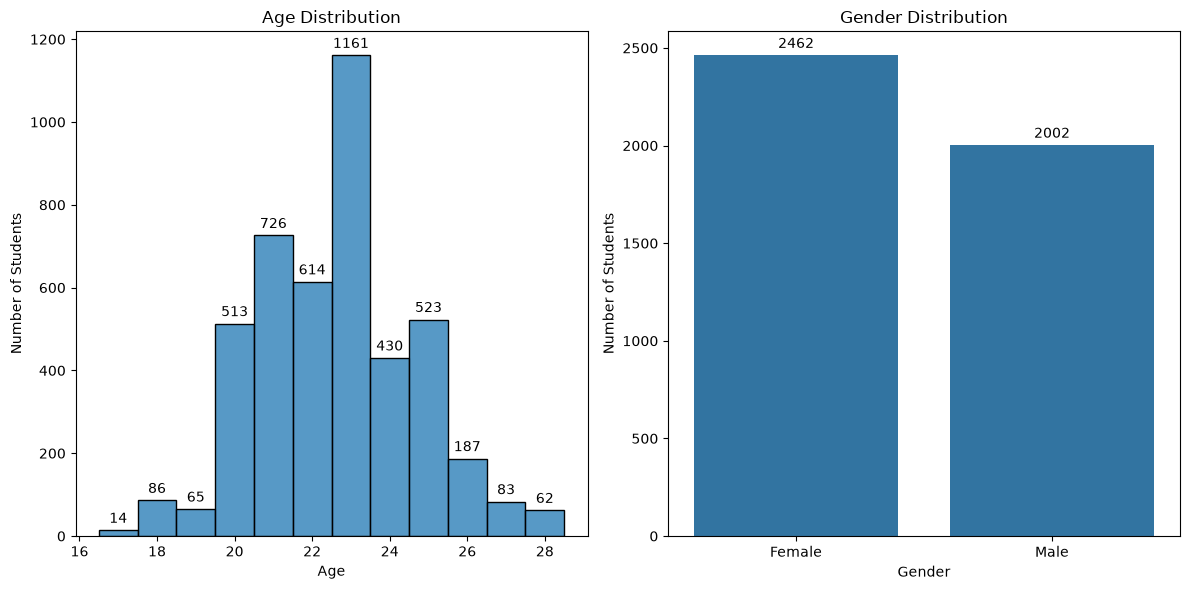

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Age Distribution
sns.histplot(
    data=df,
    x="Age",
    bins=12,
    discrete=True,
    ax=axes[0]
)
axes[0].set_title("Age Distribution")
axes[0].set_xlabel("Age")
axes[0].set_ylabel("Number of Students")

for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.0f", padding=3)

# Gender Distribution
sns.countplot(
    data=df,
    x="Gender",
    ax=axes[1]
)
axes[1].set_title("Gender Distribution")
axes[1].set_xlabel("Gender")
axes[1].set_ylabel("Number of Students")

for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.0f", padding=3)

plt.tight_layout()
plt.show()

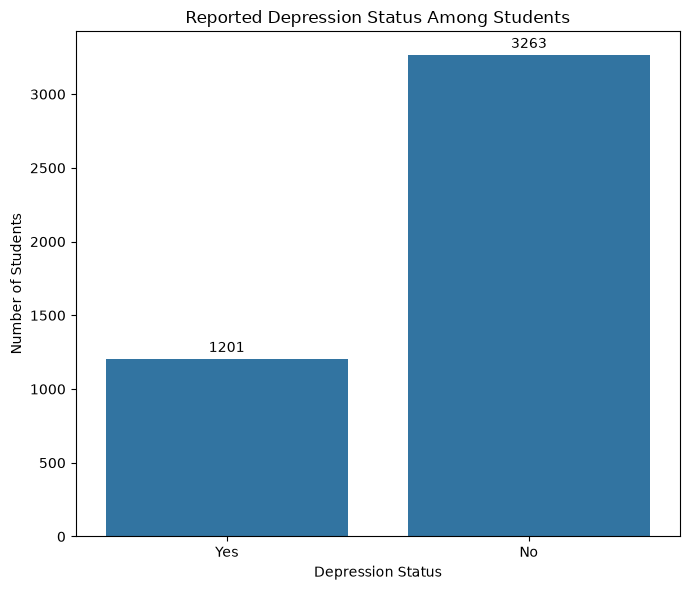

In [6]:
depression_counts = df["Depression"].value_counts()

depression_pct = (
    df["Depression"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

depression_summary = pd.DataFrame({
    "Count": depression_counts,
    "Percentage": depression_pct
})

plt.figure(figsize=(7, 6))

ax = sns.countplot(
    data=df,
    x="Depression"
)

# Add count labels above each bar
ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)

ax.set_title("Reported Depression Status Among Students")
ax.set_xlabel("Depression Status")
ax.set_ylabel("Number of Students")

plt.tight_layout()
plt.show()

In [9]:
def plot_depression_comparison(column, title, order=None):
    colors = {"No": "tab:blue", "Yes": "tab:orange"}

    # Define one consistent category order for both charts
    if order is None:
        order = df[column].value_counts().index.tolist()

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    # Count
    sns.countplot(
        data=df,
        x=column,
        hue="Depression",
        order=order,
        hue_order=["No", "Yes"],
        palette=colors,
        ax=axes[0]
    )

    axes[0].set_title(f"Number of students by {title} and Depression Status")
    axes[0].set_xlabel(title)
    axes[0].set_ylabel("Number of Students")
    axes[0].tick_params(axis="x", rotation=15)

    for container in axes[0].containers:
        axes[0].bar_label(
            container, fmt="%.0f", padding=3, fontsize=8
        )

    # Percentage
    pct = pd.crosstab(
        df[column], df["Depression"], normalize="index"
    ).mul(100).reindex(index=order, columns=["No", "Yes"], fill_value=0)

    pct.plot(
        kind="bar",
        color=[colors["No"], colors["Yes"]],
        ax=axes[1]
    )

    axes[1].set_title(f"Depression rate within each {title} (%)")
    axes[1].set_xlabel(title)
    axes[1].set_ylabel("Percentage of Students")
    axes[1].tick_params(axis="x", rotation=15)
    axes[1].legend(title="Depression Status")

    for container in axes[1].containers:
        axes[1].bar_label(
            container, fmt="%.1f%%", padding=3, fontsize=8
        )

    plt.tight_layout()
    plt.show()

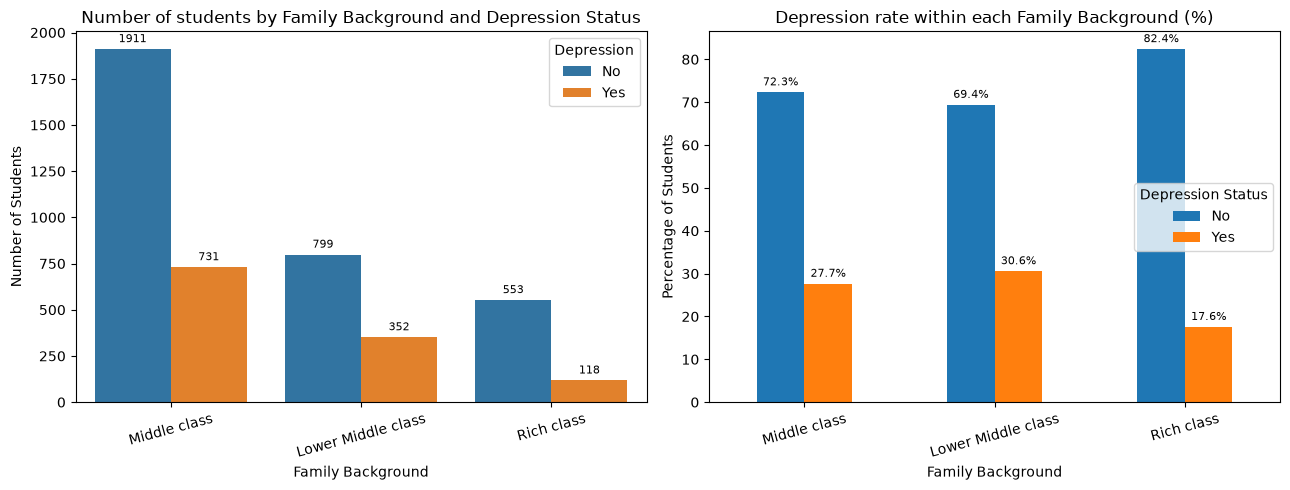

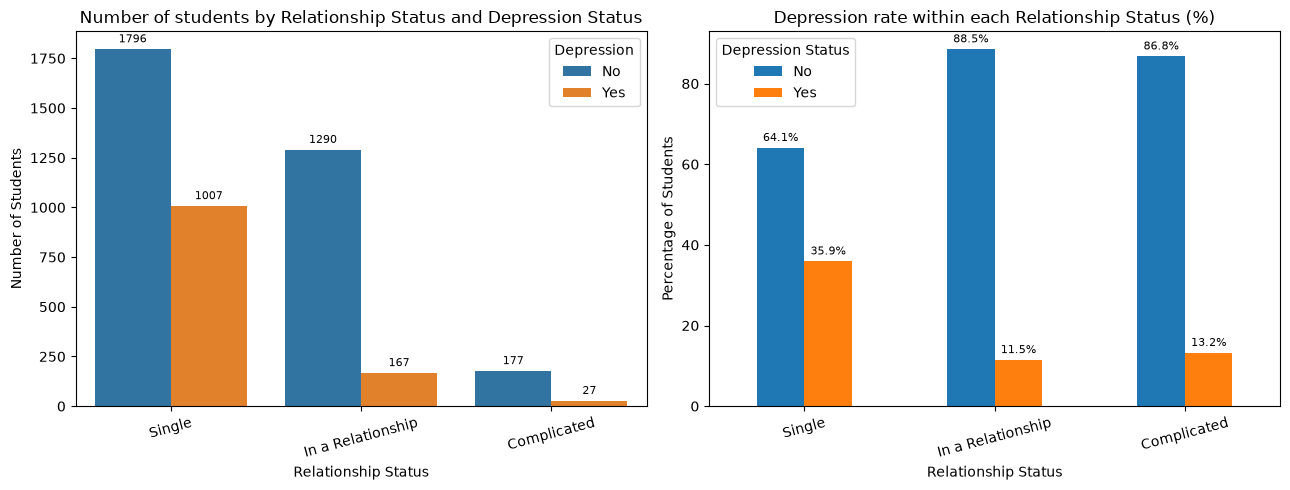

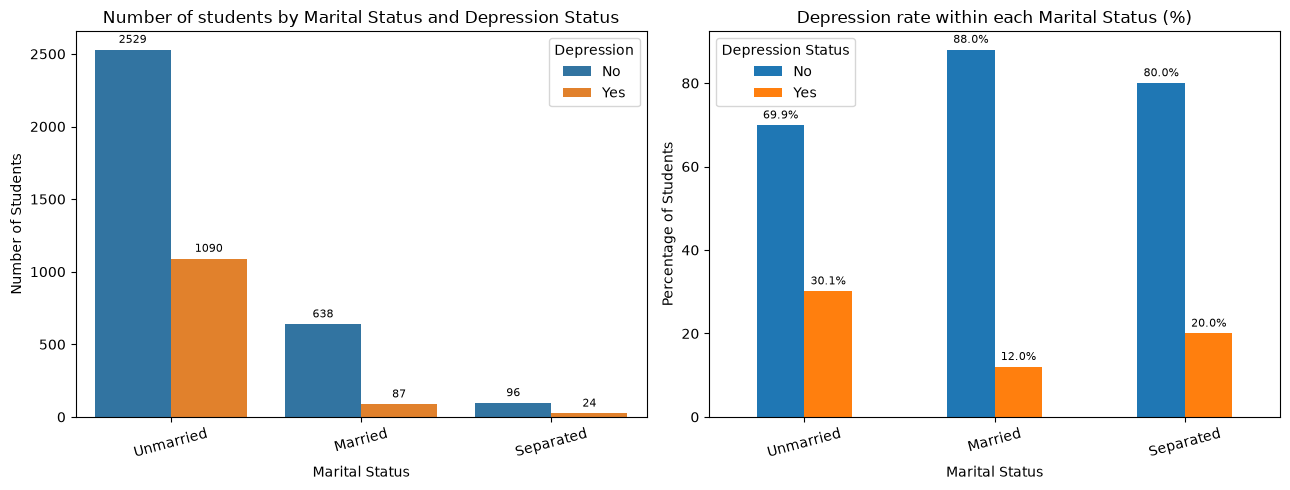

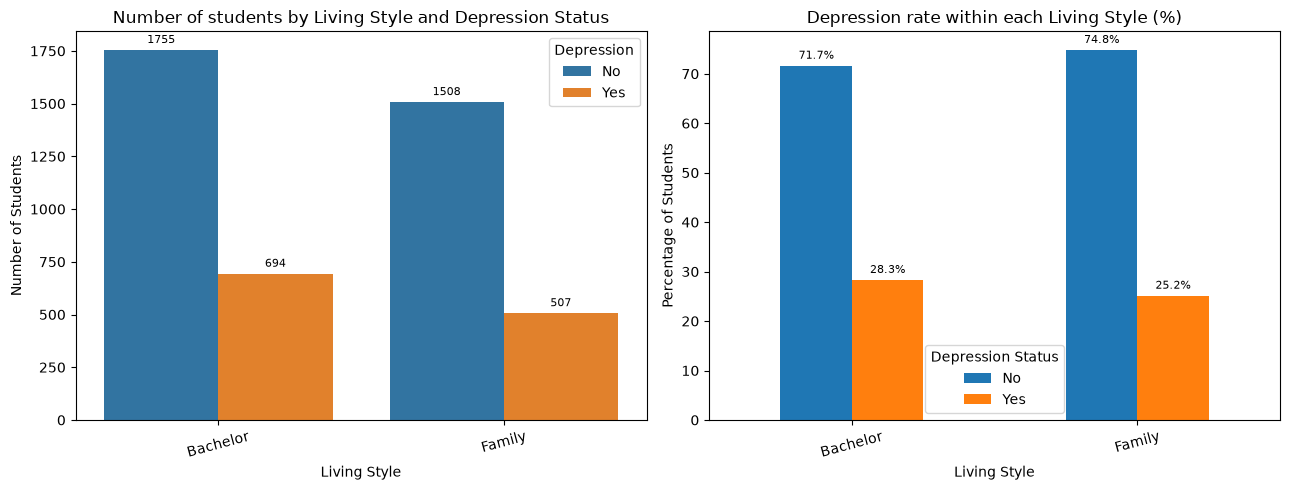

In [ ]:
#1 colonna da usare
#2 titolo
plot_depression_comparison("Family_background", "Family Background")
plot_depression_comparison("Relationship_status", "Relationship Status")
plot_depression_comparison("Marital_status", "Marital Status")
plot_depression_comparison("Living_style", "Living Style")

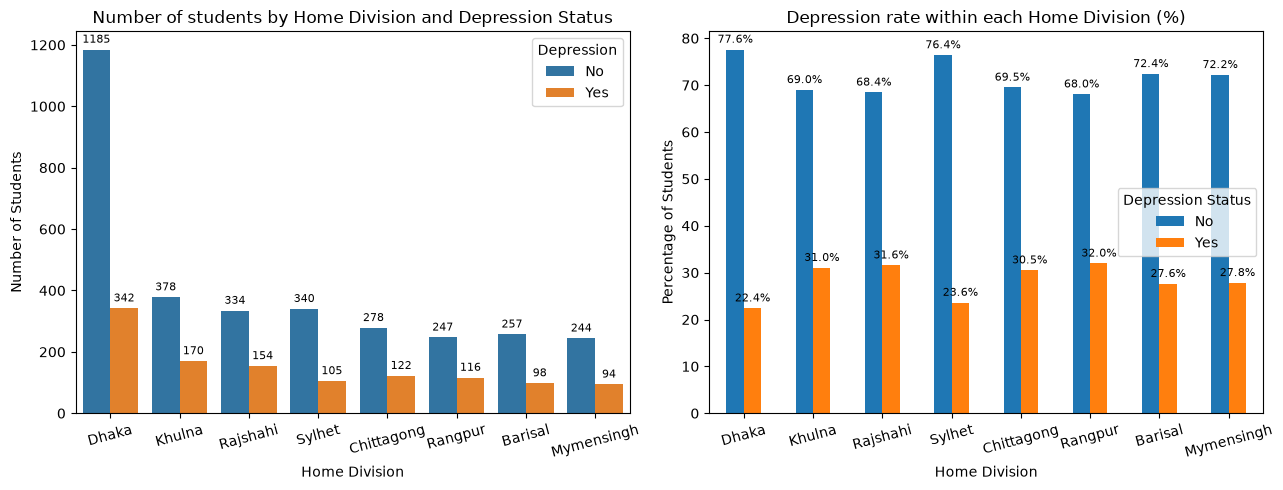

In [11]:
plot_depression_comparison("Home_division", "Home Division")


### DA ORDINARE

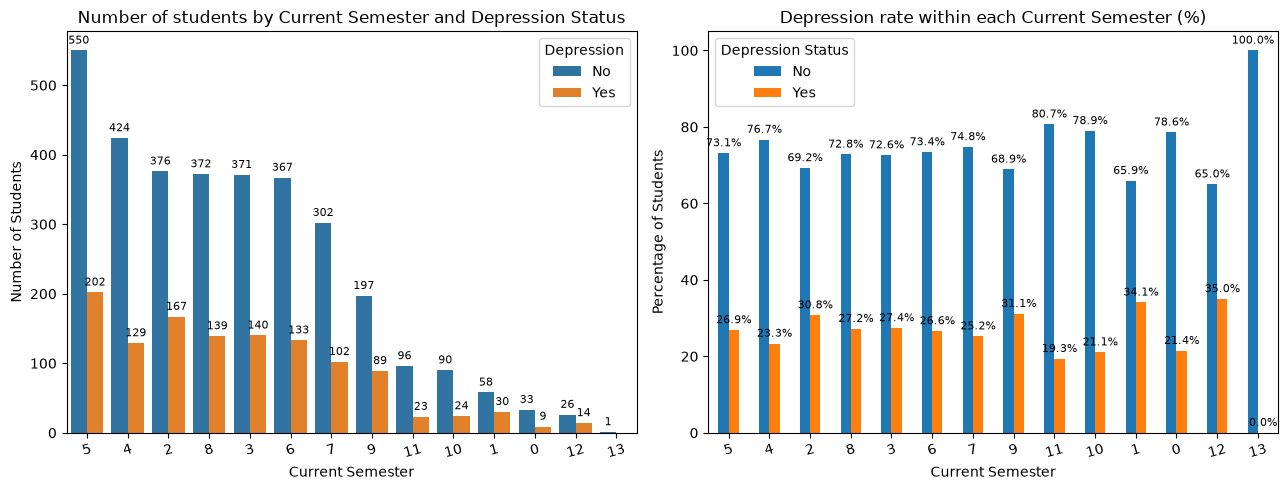

In [13]:
plot_depression_comparison("Current_semester", "Current Semester")

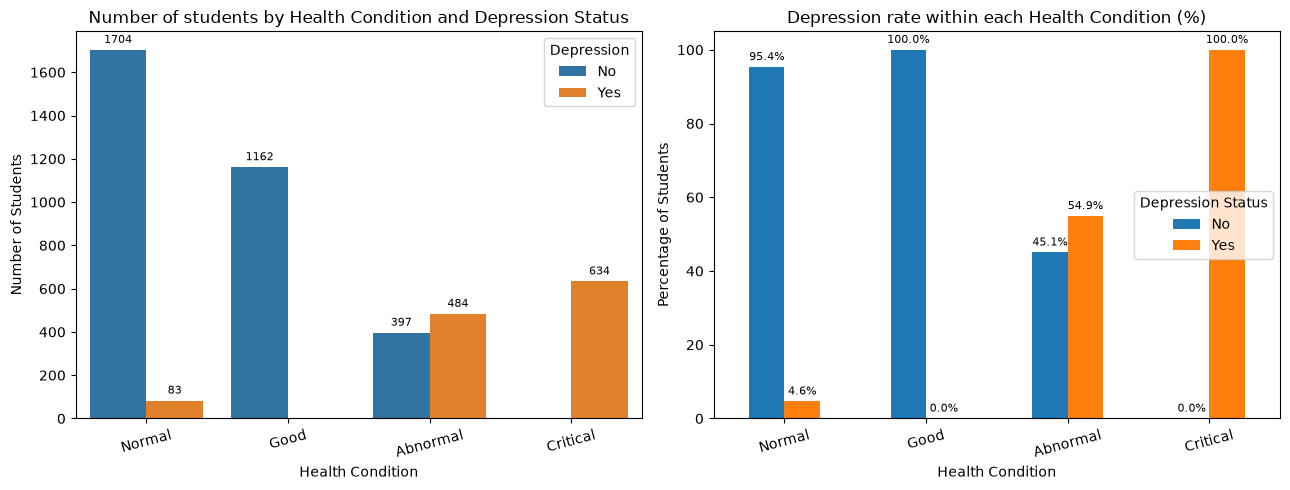

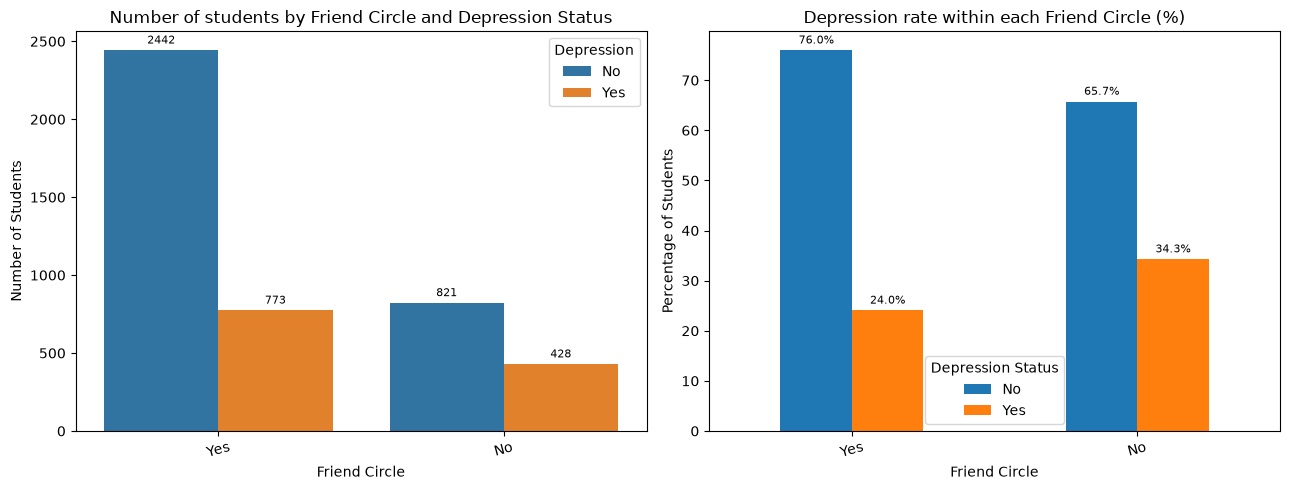

In [15]:
plot_depression_comparison("Health_condition", "Health Condition")
plot_depression_comparison("friend_circle", "Friend Circle")

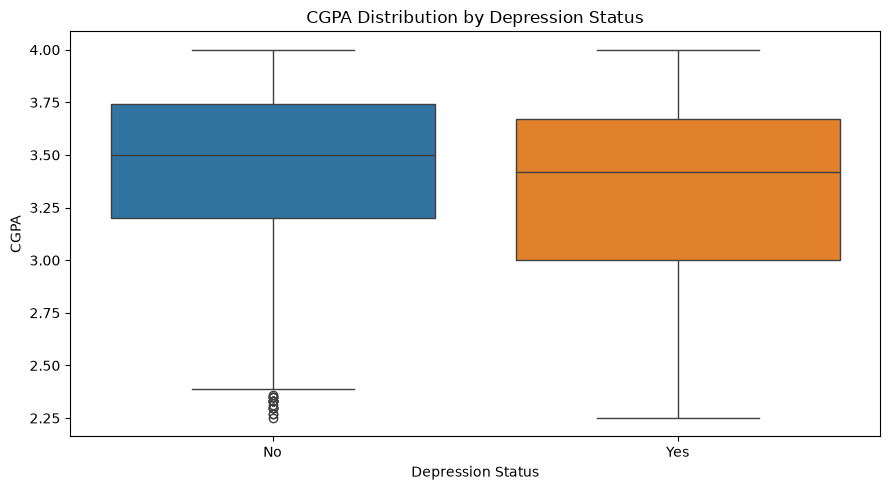

In [14]:
fig, ax = plt.subplots(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Depression",
    y="CGPA",
    hue="Depression",
    order=["No", "Yes"],
    hue_order=["No", "Yes"],
    palette={"No": "tab:blue", "Yes": "tab:orange"},
    legend=False,
    ax=ax
)

ax.set_title("CGPA Distribution by Depression Status")
ax.set_xlabel("Depression Status")
ax.set_ylabel("CGPA")

plt.tight_layout()
plt.show()

In [ ]:

summary_list = []
categorical_columns = df.select_dtypes(include=["object", "category", "string"]).columns.tolist()


for col in categorical_columns:
    summary = df.groupby(col, observed=True)["Depression"].apply(
        lambda x: (x == "Yes").mean() * 100
    ).reset_index(name="Depression_Rate")

    summary["Variable"] = col
    summary = summary.rename(columns={col: "Category"})
    summary_list.append(summary)

depression_rates = pd.concat(summary_list, ignore_index=True)

depression_rates = depression_rates[
    ["Variable", "Category", "Depression_Rate"]
].sort_values("Depression_Rate", ascending=False)

depression_rates["Depression_Rate"] = depression_rates["Depression_Rate"].round(2)

print(depression_rates.to_string(index=False))


           Variable           Category  Depression_Rate
   Health_condition           Critical           100.00
   Health_condition           Abnormal            54.94
Relationship_status             Single            35.93
      friend_circle                 No            34.27
      Home_division            Rangpur            31.96
      Home_division           Rajshahi            31.56
      Home_division             Khulna            31.02
  Family_background Lower Middle class            30.58
      Home_division         Chittagong            30.50
     Marital_status          Unmarried            30.12
       Living_style           Bachelor            28.34
      Home_division         Mymensingh            27.81
  Family_background       Middle class            27.67
      Home_division            Barisal            27.61
             Gender               Male            27.27
             Gender             Female            26.60
       Living_style             Family          

In [8]:
from scipy.stats import chi2_contingency
import numpy as np

association_results = []

for col in categorical_columns:
    contingency_table = pd.crosstab(df[col], df["Depression"])

    chi2, p_value, dof, expected = chi2_contingency(contingency_table)

    n = contingency_table.to_numpy().sum()
    r, k = contingency_table.shape

    denominator = n * min(r - 1, k - 1)
    cramers_v = np.sqrt(chi2 / denominator) if denominator > 0 else np.nan

    association_results.append({
        "Variable": col,
        "Chi-square": round(chi2, 2),
        "Degrees of Freedom": dof,
        "P-value": p_value,
        "Cramer's V": round(cramers_v, 3),
    })

association_table = pd.DataFrame(association_results)

association_table["P-value"] = association_table["P-value"].map(
    lambda p: "< 0.001" if p < 0.001 else f"{p:.3f}"
)

print(association_table.to_string(index=False))

           Variable  Chi-square  Degrees of Freedom P-value  Cramer's V
             Gender        0.22                   1   0.641       0.007
  Family_background       38.33                   2 < 0.001       0.093
Relationship_status      312.06                   2 < 0.001       0.264
     Marital_status      103.82                   2 < 0.001       0.153
       Living_style        5.51                   1   0.019       0.035
   Health_condition     2952.51                   3 < 0.001       0.813
      friend_circle       47.29                   1 < 0.001       0.103
      Home_division       35.92                   7 < 0.001       0.090


### ANALISI DEI PESI
???